# 03 - Model Training and Evaluation

Semantic segmentation of substation equipment on the **15-class ground-truth dataset**
(Gomes, 2023). This notebook trains a U-Net segmentation model and evaluates it with
standard segmentation metrics (mean IoU, per-class IoU, Dice, pixel accuracy).

**Pipeline**

1. Install and import dependencies, set a reproducible seed.
2. Locate (or extract) the dataset produced by `01_data_preparation.ipynb` /
   `02_substation_Semantic_Segmentation_EDA_V1.ipynb`.
3. Build a PyTorch dataset that converts the colour-coded masks to class-index label maps.
4. Split into train / validation / test sets (reproducible).
5. Train a U-Net (`segmentation-models-pytorch`) with an ImageNet-pretrained encoder,
   a combined Dice + Cross-Entropy loss, and mixed-precision training.
6. Track training curves, evaluate on the held-out test set, report per-class IoU, and
   visualise qualitative predictions.

> Runs in Google Colab (GPU recommended) and locally. The dataset layout follows the EDA
> notebook: `images/`, `labels_json/`, `15_masks/`, `14_masks/`, `porcelain_masks/`,
> and `classes.txt` inside the extracted dataset directory.


## 1. Environment setup

Install the segmentation and augmentation libraries. `torch` / `torchvision` are already
available in Colab. Skip this cell if your environment already has these packages.

In [1]:
# Install required packages
try:
  import segmentation_models_pytorch  # noqa: F401
  import albumentations  # noqa: F401
  print("segmentation-models-pytorch and albumentations already available.")
except ImportError:
  import sys
  !{sys.executable} -m pip install -q "segmentation-models-pytorch==0.3.4" "albumentations==1.4.18"
  print("Installed segmentation-models-pytorch and albumentations.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Installed segmentation-models-pytorch and albumentations.


## 2. Imports, configuration and reproducibility

In [2]:
import os
import random
import json
import time
from pathlib import Path
from dataclasses import dataclass, field

import numpy as np
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import pandas as pd

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# OpenCV in worker processes should not grab all threads.
cv2.setNumThreads(0)


@dataclass
class Config:
    # Data
    image_size: int = 512          # square input fed to the network
    val_fraction: float = 0.15
    test_fraction: float = 0.15
    max_samples: int | None = None  # set to e.g. 200 for a quick smoke test; None = full dataset

    # Model
    encoder_name: str = "resnet34"
    encoder_weights: str = "imagenet"
    architecture: str = "unet"      # "unet" | "unetpp" | "deeplabv3plus"

    # Training
    epochs: int = 30
    batch_size: int = 8
    num_workers: int = 2
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    early_stopping_patience: int = 8

    seed: int = 42
    checkpoint_path: str = "best_model.pth"


cfg = Config()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/albumentations/__init__.py:13: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.18). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


PyTorch: 2.14.1+cu130
Device : cuda
GPU    : Tesla T4


## 3. Locate (or extract) the dataset

The EDA notebook extracts the archive to `/content/substation_semantic_dataset` in Colab.
This cell reuses that directory if present, otherwise extracts the downloaded archive
(`substation-semantic-dataset.zip`) produced by `01_data_preparation.ipynb`.

Set `DATASET_DIR` manually if your data lives somewhere else.

In [3]:
from zipfile import ZipFile
import urllib.request
from pathlib import Path

zip_url = "https://zenodo.org/records/7884270/files/substation-semantic-dataset.zip?download=1"

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REQUIRED_SUBDIRS = ["images", "labels_json", "15_masks"]


def looks_like_dataset(path: Path) -> bool:
    return path.is_dir() and all((path / sub).is_dir() for sub in REQUIRED_SUBDIRS)


# Target directory in Google Colab
DATASET_DIR = Path("/content/substation_semantic_dataset")

if not looks_like_dataset(DATASET_DIR):
    print("Dataset not found or incomplete. Downloading dataset from Zenodo...")
    zip_url = "https://zenodo.org/records/7884270/files/substation-semantic-dataset.zip?download=1"
    archive_path = Path("/content/substation-semantic-dataset.zip")

    # Download the archive
    urllib.request.urlretrieve(zip_url, archive_path)
    print("Download finished. Extracting dataset...")

    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    with ZipFile(archive_path) as zf:
        zf.extractall(DATASET_DIR)

    # Clean up the zip file to save space
    if archive_path.exists():
        archive_path.unlink()
    print("Extraction completed!")

# If nested under a subdirectory after extraction, find it
if not looks_like_dataset(DATASET_DIR):
    for child in DATASET_DIR.iterdir():
        if looks_like_dataset(child):
            DATASET_DIR = child
            break

if not looks_like_dataset(DATASET_DIR):
    raise FileNotFoundError("Dataset directory is missing the expected subfolders.")

IMAGE_DIR = DATASET_DIR / "images"
MASK_DIR = DATASET_DIR / "15_masks"
print("Dataset directory:", DATASET_DIR)
print("Images           :", IMAGE_DIR)
print("Masks (15-class) :", MASK_DIR)

Dataset not found or incomplete. Downloading dataset from Zenodo...
Download finished. Extracting dataset...
Extraction completed!
Dataset directory: /content/substation_semantic_dataset
Images           : /content/substation_semantic_dataset/images
Masks (15-class) : /content/substation_semantic_dataset/15_masks


## 4. Classes and colour palette

`classes.txt` lists 16 names: `Background` plus 15 equipment classes. The masks are
colour-coded PNGs. The original authors swap channels before saving, so OpenCV
(`cv2.imread`, which returns BGR) reads back the **reversed** author RGB palette. We build
a colour->class-index lookup to turn each colour mask into an integer label map.

In [4]:
# Author RGB palette, in class-index order (from the dataset's json2png.py / EDA notebook).
AUTHOR_PALETTE_RGB = [
    (0, 0, 0),        # 0  Background
    (162, 0, 255),    # 1  Open blade disconnect switch
    (97, 16, 162),    # 2  Closed blade disconnect switch
    (81, 162, 0),     # 3  Open tandem disconnect switch
    (48, 97, 165),    # 4  Closed tandem disconnect switch
    (121, 121, 121),  # 5  Breaker
    (255, 97, 178),   # 6  Fuse disconnect switch
    (154, 32, 121),   # 7  Glass disc insulator
    (255, 255, 125),  # 8  Porcelain pin insulator
    (162, 243, 162),  # 9  Muffle
    (143, 211, 255),  # 10 Lightning arrester
    (40, 0, 186),     # 11 Recloser
    (255, 182, 0),    # 12 Power transformer
    (138, 138, 0),    # 13 Current transformer
    (162, 48, 0),     # 14 Potential transformer
    (162, 0, 96),     # 15 Tripolar disconnect switch
]

# Read class names if available, otherwise fall back to the documented list.
FALLBACK_NAMES = [
    "Background", "Open blade disconnect switch", "Closed blade disconnect switch",
    "Open tandem disconnect switch", "Closed tandem disconnect switch", "Breaker",
    "Fuse disconnect switch", "Glass disc insulator", "Porcelain pin insulator",
    "Muffle", "Lightning arrester", "Recloser", "Power transformer",
    "Current transformer", "Potential transformer", "Tripolar disconnect switch",
]

classes_file = DATASET_DIR / "classes.txt"
if classes_file.is_file():
    CLASS_NAMES = [ln.strip() for ln in classes_file.read_text(encoding="utf-8-sig").splitlines() if ln.strip()]
else:
    CLASS_NAMES = FALLBACK_NAMES

assert len(CLASS_NAMES) == len(AUTHOR_PALETTE_RGB), (len(CLASS_NAMES), len(AUTHOR_PALETTE_RGB))
NUM_CLASSES = len(CLASS_NAMES)

# cv2.imread returns BGR; the mask colours equal the reversed author RGB tuples.
PALETTE_BGR = np.array([rgb[::-1] for rgb in AUTHOR_PALETTE_RGB], dtype=np.uint8)
# RGB palette for visualisation of label maps.
PALETTE_RGB = np.array(AUTHOR_PALETTE_RGB, dtype=np.uint8)


def encode_bgr(arr: np.ndarray) -> np.ndarray:
    v = arr.astype(np.uint32)
    return (v[..., 0] << 16) | (v[..., 1] << 8) | v[..., 2]


_palette_codes = encode_bgr(PALETTE_BGR)
assert len(np.unique(_palette_codes)) == NUM_CLASSES, "Palette has duplicate colours."
# Map each palette colour code to its class index; everything else -> Background (0).
_code_to_index = {int(c): i for i, c in enumerate(_palette_codes)}


def color_mask_to_index(mask_bgr: np.ndarray) -> np.ndarray:
    """Convert a BGR colour mask (as read by cv2.imread) to an int class-index map."""
    codes = encode_bgr(mask_bgr)
    index_map = np.zeros(codes.shape, dtype=np.int64)
    for code, class_index in _code_to_index.items():
        index_map[codes == code] = class_index
    return index_map


print(f"{NUM_CLASSES} classes:")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i:>2}: {name}")

16 classes:
   0: Background
   1: Open blade disconnect switch
   2: Closed blade disconnect switch
   3: Open tandem disconnect switch
   4: Closed tandem disconnect switch
   5: Breaker
   6: Fuse disconnect switch
   7: Glass disc insulator
   8: Porcelain pin insulator
   9: Muffle
  10: Lightning arrester
  11: Recloser
  12: Power transformer
  13: Current transformer
  14: Potential transformer
  15: Tripolar disconnect switch


## 5. Pair files and build reproducible splits

Each image is matched to its `15_masks` PNG by filename stem. Images with both parts are
shuffled with a fixed seed and split into train / validation / test.

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg"}

image_paths = sorted(p for p in IMAGE_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
mask_by_stem = {p.stem: p for p in MASK_DIR.iterdir() if p.is_file() and p.suffix.lower() == ".png"}

pairs = [(img, mask_by_stem[img.stem]) for img in image_paths if img.stem in mask_by_stem]
missing = [img.name for img in image_paths if img.stem not in mask_by_stem]
print(f"Images: {len(image_paths)} | paired with masks: {len(pairs)} | missing masks: {len(missing)}")

rng = random.Random(cfg.seed)
rng.shuffle(pairs)

if cfg.max_samples is not None:
    pairs = pairs[: cfg.max_samples]
    print(f"Subsampled to {len(pairs)} pairs (cfg.max_samples).")

n_total = len(pairs)
n_test = int(round(n_total * cfg.test_fraction))
n_val = int(round(n_total * cfg.val_fraction))
test_pairs = pairs[:n_test]
val_pairs = pairs[n_test:n_test + n_val]
train_pairs = pairs[n_test + n_val:]

print(f"Train: {len(train_pairs)} | Val: {len(val_pairs)} | Test: {len(test_pairs)}")

Images: 1660 | paired with masks: 1660 | missing masks: 0
Train: 1162 | Val: 249 | Test: 249


## 6. Dataset, augmentation and dataloaders

The dataset reads the image (BGR->RGB), converts the colour mask to a class-index map, then
applies Albumentations transforms (geometric/photometric augmentation on train only,
resize + ImageNet normalisation on all splits). Masks use nearest-neighbour resizing to
preserve class indices.

In [6]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def build_transforms(train: bool) -> A.Compose:
    if train:
        return A.Compose([
            A.Resize(cfg.image_size, cfg.image_size),
            A.HorizontalFlip(p=0.5),
            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15,
                               border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0, p=0.5),
            A.RandomBrightnessContrast(p=0.3),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ])
    return A.Compose([
        A.Resize(cfg.image_size, cfg.image_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


class SubstationSegmentationDataset(Dataset):
    def __init__(self, pairs, transforms):
        self.pairs = pairs
        self.transforms = transforms

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]
        # cv2.imread applies EXIF orientation by default, keeping image and mask aligned.
        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image_bgr is None:
            raise RuntimeError(f"Could not read image: {image_path}")
        image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

        mask_bgr = cv2.imread(str(mask_path), cv2.IMREAD_COLOR)
        if mask_bgr is None:
            raise RuntimeError(f"Could not read mask: {mask_path}")
        mask = color_mask_to_index(mask_bgr)

        out = self.transforms(image=image, mask=mask)
        image_t = out["image"]
        mask_t = out["mask"].long()
        return image_t, mask_t


train_ds = SubstationSegmentationDataset(train_pairs, build_transforms(train=True))
val_ds = SubstationSegmentationDataset(val_pairs, build_transforms(train=False))
test_ds = SubstationSegmentationDataset(test_pairs, build_transforms(train=False))

pin = DEVICE.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                          num_workers=cfg.num_workers, pin_memory=pin, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False,
                        num_workers=cfg.num_workers, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False,
                         num_workers=cfg.num_workers, pin_memory=pin)

print("Batches  ->  train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

Batches  ->  train: 145 | val: 32 | test: 32


### Sanity check: visualise a training sample

Un-normalise one image and overlay its colour-coded ground-truth mask.

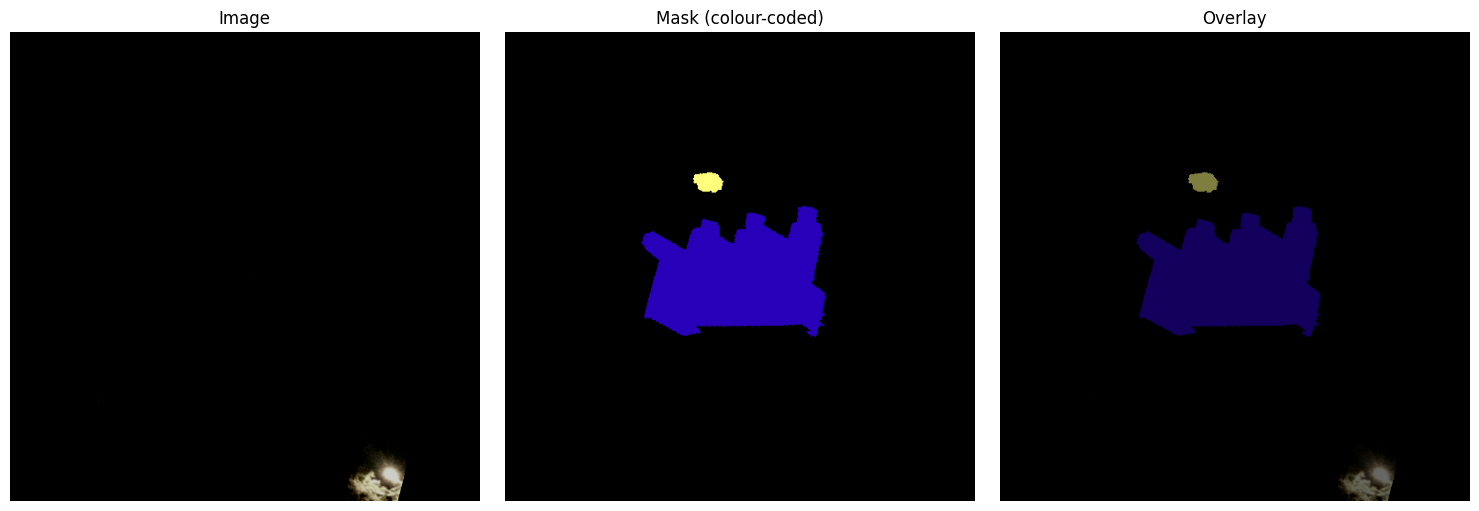

Classes present in this sample: ['Background', 'Porcelain pin insulator', 'Recloser']


In [7]:
def denormalize(image_t: torch.Tensor) -> np.ndarray:
    img = image_t.permute(1, 2, 0).cpu().numpy()
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)


def index_to_rgb(index_map: np.ndarray) -> np.ndarray:
    return PALETTE_RGB[index_map]


img_t, mask_t = train_ds[0]
img_np = denormalize(img_t)
mask_np = mask_t.cpu().numpy()
mask_rgb = index_to_rgb(mask_np)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_np); axes[0].set_title("Image"); axes[0].axis("off")
axes[1].imshow(mask_rgb); axes[1].set_title("Mask (colour-coded)"); axes[1].axis("off")
axes[2].imshow(img_np); axes[2].imshow(mask_rgb, alpha=0.5)
axes[2].set_title("Overlay"); axes[2].axis("off")
plt.tight_layout(); plt.show()

present = np.unique(mask_np)
print("Classes present in this sample:", [CLASS_NAMES[i] for i in present])

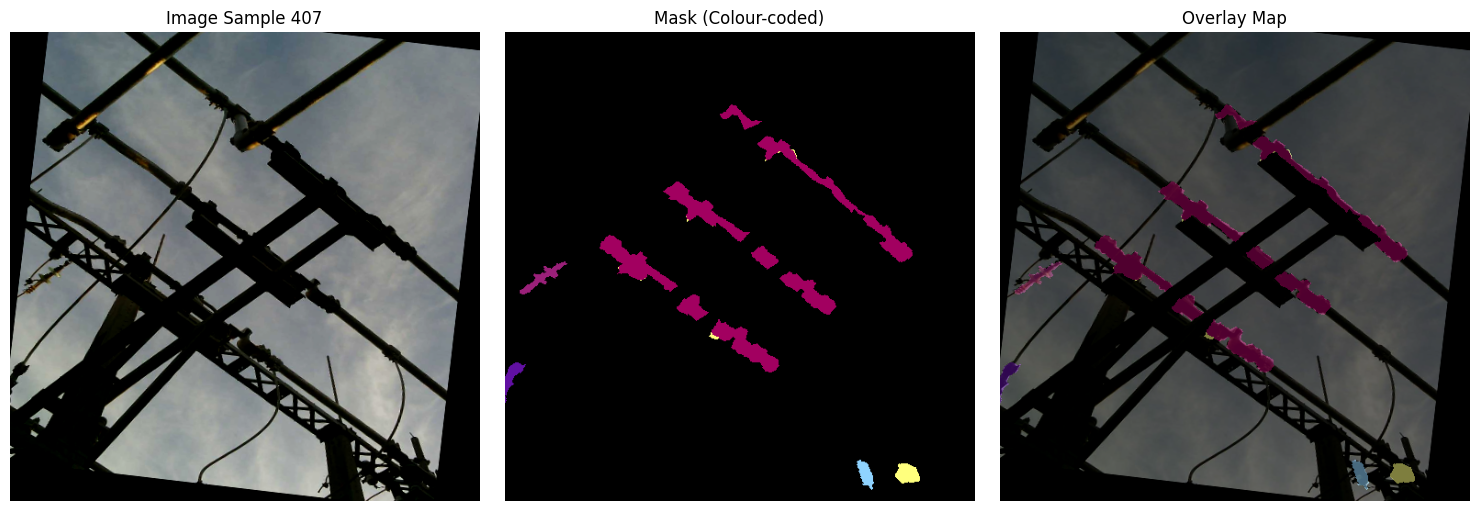

Classes present in this sample:
  - Background
  - Closed blade disconnect switch
  - Glass disc insulator
  - Porcelain pin insulator
  - Lightning arrester
  - Tripolar disconnect switch


In [8]:
import random

# Select a random sample from the dataset
idx = random.randint(0, len(train_ds) - 1)
img_t, mask_t = train_ds[idx]

# Prepare the visualization
img_np = denormalize(img_t)
mask_np = mask_t.cpu().numpy()
mask_rgb = index_to_rgb(mask_np)

# Create a side-by-side plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_np)
axes[0].set_title(f"Image Sample {idx}")
axes[0].axis("off")

axes[1].imshow(mask_rgb)
axes[1].set_title("Mask (Colour-coded)")
axes[1].axis("off")

# Overlay mask with alpha transparency on top of the original image
axes[2].imshow(img_np)
axes[2].imshow(mask_rgb, alpha=0.5)
axes[2].set_title("Overlay Map")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Display the classes actually present in this random sample
present_classes = np.unique(mask_np)
print("Classes present in this sample:")
for cls_idx in present_classes:
    print(f"  - {CLASS_NAMES[cls_idx]}")

## 7. Model, loss and optimiser

A U-Net with an ImageNet-pretrained encoder from `segmentation-models-pytorch`. The loss
combines **Dice** (robust to the strong class imbalance) and **Cross-Entropy**. Adam with a
cosine-annealing schedule.

In [9]:
def build_model(cfg: Config) -> nn.Module:
    arch = cfg.architecture.lower()
    common = dict(encoder_name=cfg.encoder_name, encoder_weights=cfg.encoder_weights,
                  in_channels=3, classes=NUM_CLASSES)
    if arch == "unet":
        return smp.Unet(**common)
    if arch == "unetpp":
        return smp.UnetPlusPlus(**common)
    if arch == "deeplabv3plus":
        return smp.DeepLabV3Plus(**common)
    raise ValueError(f"Unknown architecture: {cfg.architecture}")


model = build_model(cfg).to(DEVICE)

dice_loss = smp.losses.DiceLoss(mode="multiclass")
ce_loss = nn.CrossEntropyLoss()


def criterion(logits, targets):
    return dice_loss(logits, targets) + ce_loss(logits, targets)


optimizer = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs)
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{cfg.architecture} / {cfg.encoder_name}: {n_params:.1f}M parameters, {NUM_CLASSES} output classes.")

Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 393MB/s]


unet / resnet34: 24.4M parameters, 16 output classes.


/tmp/ipykernel_1927/1102334961.py:26: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")


## 8. Metrics

We accumulate per-class true-positive / false-positive / false-negative pixel counts across
a whole split with `smp.metrics`, then derive per-class IoU, macro mean IoU, mean Dice, and
pixel accuracy. Classes absent from a split are excluded from the macro averages.

In [10]:
class SegMetrics:
    """Accumulate per-class TP/FP/FN over an epoch and compute IoU / Dice / accuracy."""

    def __init__(self, num_classes: int):
        self.num_classes = num_classes
        self.reset()

    def reset(self):
        self.tp = torch.zeros(self.num_classes, dtype=torch.long)
        self.fp = torch.zeros(self.num_classes, dtype=torch.long)
        self.fn = torch.zeros(self.num_classes, dtype=torch.long)
        self.tn = torch.zeros(self.num_classes, dtype=torch.long)

    @torch.no_grad()
    def update(self, preds: torch.Tensor, targets: torch.Tensor):
        # preds, targets: (B, H, W) integer label maps.
        tp, fp, fn, tn = smp.metrics.get_stats(
            preds, targets, mode="multiclass", num_classes=self.num_classes
        )
        self.tp += tp.sum(0).cpu()
        self.fp += fp.sum(0).cpu()
        self.fn += fn.sum(0).cpu()
        self.tn += tn.sum(0).cpu()

    def per_class_iou(self):
        denom = (self.tp + self.fp + self.fn).float()
        iou = torch.where(denom > 0, self.tp.float() / denom, torch.full_like(denom, float("nan")))
        return iou

    def per_class_dice(self):
        denom = (2 * self.tp + self.fp + self.fn).float()
        dice = torch.where(denom > 0, 2 * self.tp.float() / denom, torch.full_like(denom, float("nan")))
        return dice

    def summary(self):
        iou = self.per_class_iou()
        dice = self.per_class_dice()
        mean_iou = torch.nanmean(iou).item()
        mean_dice = torch.nanmean(dice).item()
        total = (self.tp + self.fn).sum().float()
        pixel_acc = (self.tp.sum().float() / total).item() if total > 0 else float("nan")
        return {"mean_iou": mean_iou, "mean_dice": mean_dice, "pixel_acc": pixel_acc}

## 9. Training loop

Mixed-precision training, validation after each epoch, best-checkpoint saving on validation
mean IoU, and early stopping.

In [ ]:
def run_epoch(loader, train: bool):
    model.train(train)
    metrics = SegMetrics(NUM_CLASSES)
    running_loss = 0.0
    n_batches = 0

    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(train):
            with torch.cuda.amp.autocast(enabled=DEVICE.type == "cuda"):
                logits = model(images)
                loss = criterion(logits, masks)

            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        preds = logits.argmax(dim=1)
        metrics.update(preds.detach(), masks.detach())
        running_loss += loss.item()
        n_batches += 1

    stats = metrics.summary()
    stats["loss"] = running_loss / max(n_batches, 1)
    return stats, metrics


history = {"train_loss": [], "val_loss": [], "train_miou": [], "val_miou": []}
best_val_miou = -1.0
epochs_without_improvement = 0

for epoch in range(1, cfg.epochs + 1):
    t0 = time.time()
    train_stats, _ = run_epoch(train_loader, train=True)
    val_stats, _ = run_epoch(val_loader, train=False)
    scheduler.step()

    history["train_loss"].append(train_stats["loss"])
    history["val_loss"].append(val_stats["loss"])
    history["train_miou"].append(train_stats["mean_iou"])
    history["val_miou"].append(val_stats["mean_iou"])

    improved = val_stats["mean_iou"] > best_val_miou
    if improved:
        best_val_miou = val_stats["mean_iou"]
        epochs_without_improvement = 0
        torch.save({"model_state": model.state_dict(),
                    "config": cfg.__dict__,
                    "class_names": CLASS_NAMES,
                    "val_miou": best_val_miou,
                    "epoch": epoch}, cfg.checkpoint_path)
    else:
        epochs_without_improvement += 1

    print(f"Epoch {epoch:02d}/{cfg.epochs} "
          f"| train loss {train_stats['loss']:.4f} mIoU {train_stats['mean_iou']:.4f} "
          f"| val loss {val_stats['loss']:.4f} mIoU {val_stats['mean_iou']:.4f} "
          f"| {time.time() - t0:.0f}s {'* best' if improved else ''}")

    if epochs_without_improvement >= cfg.early_stopping_patience:
        print(f"Early stopping: no val mIoU improvement for {cfg.early_stopping_patience} epochs.")
        break

print(f"\nBest validation mean IoU: {best_val_miou:.4f} (saved to {cfg.checkpoint_path})")

/tmp/ipykernel_1927/2219449438.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == "cuda"):


Epoch 01/30 | train loss 1.3871 mIoU 0.0602 | val loss 1.1110 mIoU 0.0707 | 212s * best
Epoch 02/30 | train loss 1.0661 mIoU 0.0815 | val loss 1.0372 mIoU 0.0979 | 206s * best
Epoch 03/30 | train loss 0.9964 mIoU 0.1219 | val loss 1.0733 mIoU 0.1007 | 206s * best
Epoch 04/30 | train loss 0.9687 mIoU 0.1330 | val loss 1.0210 mIoU 0.1304 | 208s * best
Epoch 05/30 | train loss 0.9245 mIoU 0.1524 | val loss 0.8785 mIoU 0.1751 | 205s * best
Epoch 06/30 | train loss 0.9017 mIoU 0.1600 | val loss 0.8959 mIoU 0.1782 | 206s * best
Epoch 07/30 | train loss 0.8830 mIoU 0.1773 | val loss 0.8521 mIoU 0.1924 | 205s * best
Epoch 08/30 | train loss 0.8443 mIoU 0.1969 | val loss 0.9315 mIoU 0.1621 | 207s 
Epoch 09/30 | train loss 0.8289 mIoU 0.2086 | val loss 0.8034 mIoU 0.2217 | 207s * best
Epoch 10/30 | train loss 0.8259 mIoU 0.2107 | val loss 0.8413 mIoU 0.2105 | 203s 
Epoch 11/30 | train loss 0.7968 mIoU 0.2239 | val loss 0.8319 mIoU 0.2112 | 206s 
Epoch 12/30 | train loss 0.7678 mIoU 0.2430 | val 

## 10. Training curves

In [ ]:
epochs_ran = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(epochs_ran, history["train_loss"], label="train")
axes[0].plot(epochs_ran, history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(epochs_ran, history["train_miou"], label="train")
axes[1].plot(epochs_ran, history["val_miou"], label="val")
axes[1].set_title("Mean IoU"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 11. Evaluation on the held-out test set

Reload the best checkpoint and compute overall metrics plus a per-class IoU / Dice table.

In [ ]:
checkpoint = torch.load(cfg.checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()
print(f"Loaded best checkpoint from epoch {checkpoint['epoch']} (val mIoU {checkpoint['val_miou']:.4f}).")

test_metrics = SegMetrics(NUM_CLASSES)
with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == "cuda"):
            logits = model(images)
        preds = logits.argmax(dim=1)
        test_metrics.update(preds, masks)

summary = test_metrics.summary()
print("\nTest set results")
print(f"  Mean IoU      : {summary['mean_iou']:.4f}")
print(f"  Mean Dice     : {summary['mean_dice']:.4f}")
print(f"  Pixel accuracy: {summary['pixel_acc']:.4f}")

In [ ]:
iou = test_metrics.per_class_iou().numpy()
dice = test_metrics.per_class_dice().numpy()
support = (test_metrics.tp + test_metrics.fn).numpy()  # ground-truth pixels per class

per_class_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "IoU": iou,
    "Dice": dice,
    "GT_pixels": support,
})
per_class_df = per_class_df.sort_values("IoU", ascending=False, na_position="last").reset_index(drop=True)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(per_class_df.to_string(index=False))

In [ ]:
# Per-class IoU bar chart (classes present in the test set).
plot_df = per_class_df.dropna(subset=["IoU"]).sort_values("IoU")
plt.figure(figsize=(10, 7))
plt.barh(plot_df["class"], plot_df["IoU"], color="#4C78A8")
plt.axvline(summary["mean_iou"], color="crimson", linestyle="--", label=f"mean IoU = {summary['mean_iou']:.3f}")
plt.xlabel("IoU"); plt.title("Per-class IoU on the test set"); plt.legend()
plt.tight_layout(); plt.show()

## 12. Qualitative predictions

Overlay predictions against ground truth for a few test images.

In [ ]:
def predict_batch(images):
    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=DEVICE.type == "cuda"):
            logits = model(images.to(DEVICE))
        return logits.argmax(dim=1).cpu().numpy()


n_show = min(4, len(test_ds))
fig, axes = plt.subplots(n_show, 3, figsize=(15, 5 * n_show))
if n_show == 1:
    axes = axes[None, :]

for row in range(n_show):
    img_t, mask_t = test_ds[row]
    pred = predict_batch(img_t.unsqueeze(0))[0]
    img_np = denormalize(img_t)

    axes[row, 0].imshow(img_np); axes[row, 0].set_title("Image"); axes[row, 0].axis("off")
    axes[row, 1].imshow(index_to_rgb(mask_t.numpy())); axes[row, 1].set_title("Ground truth"); axes[row, 1].axis("off")
    axes[row, 2].imshow(index_to_rgb(pred)); axes[row, 2].set_title("Prediction"); axes[row, 2].axis("off")

plt.tight_layout(); plt.show()

## 13. Save artefacts and summary

The best model weights are already in `best_model.pth`. Save the metrics and a legend of
class colours alongside it.

In [ ]:
results = {
    "architecture": cfg.architecture,
    "encoder": cfg.encoder_name,
    "num_classes": NUM_CLASSES,
    "test_mean_iou": summary["mean_iou"],
    "test_mean_dice": summary["mean_dice"],
    "test_pixel_accuracy": summary["pixel_acc"],
    "best_val_mean_iou": best_val_miou,
    "per_class_iou": {CLASS_NAMES[i]: (None if np.isnan(iou[i]) else float(iou[i])) for i in range(NUM_CLASSES)},
}
with open("test_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("Saved:")
print("  best_model.pth    - best model weights + config")
print("  test_results.json - test metrics and per-class IoU")
print(f"\nFinal test mean IoU: {summary['mean_iou']:.4f} | mean Dice: {summary['mean_dice']:.4f} | pixel acc: {summary['pixel_acc']:.4f}")

## Notes and next steps

- **Class imbalance** is severe (porcelain pin insulators dominate; several switch classes
  are rare). Rare classes will show lower IoU. Options: class-weighted loss, Focal/Tversky
  loss, oversampling images containing rare classes, or heavier augmentation.
- **Input size / resolution**: images vary from ~0.3 to ~16 MP. A fixed 512x512 resize is a
  speed/accuracy compromise; try larger sizes or tiling for small objects.
- **Architecture / encoder**: switch via `cfg.architecture` (`unet`, `unetpp`,
  `deeplabv3plus`) and `cfg.encoder_name` (e.g. `resnet50`, `efficientnet-b3`).
- **Quick smoke test**: set `cfg.max_samples = 200` and `cfg.epochs = 3` to validate the
  pipeline end-to-end before a full run.
- **Reproducibility**: splits and training are seeded via `cfg.seed`.
